# Laboratorio 08. Red neuronal desde cero

Clasificación de gatos y no gatos con una red escrita en NumPy y los datos del curso.

Entrada: (12288, 209) | salida: (1, 209) | prueba: (12288, 50)


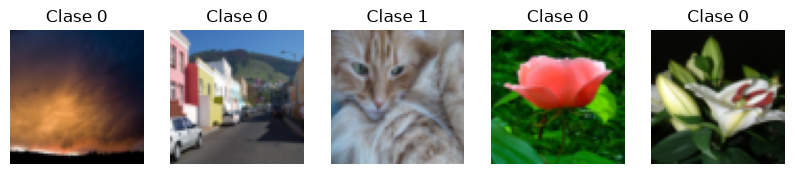

In [1]:
# Cargamos los datos del curso sin depender de una descarga.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits

semestre = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'Laboratorios/datasets/cat_not_cat').exists())
ruta = semestre / 'Laboratorios/datasets/cat_not_cat'
with h5py.File(ruta / 'train_catvnoncat.h5') as archivo:
    imagenes = archivo['train_set_x'][:]
    etiquetas = archivo['train_set_y'][:]
with h5py.File(ruta / 'test_catvnoncat.h5') as archivo:
    imagenes_test = archivo['test_set_x'][:]
    etiquetas_test = archivo['test_set_y'][:]

# Cada columna será una imagen; dividimos por 255 para llevar los píxeles a [0, 1].
X = imagenes.reshape(len(imagenes), -1).T / 255.
Y = etiquetas.reshape(1, -1)
X_test = imagenes_test.reshape(len(imagenes_test), -1).T / 255.
Y_test = etiquetas_test.reshape(1, -1)
it, iv = train_test_split(np.arange(X.shape[1]), test_size=.2,
                         stratify=etiquetas, random_state=42)
print('Entrada:', X.shape, '| salida:', Y.shape, '| prueba:', X_test.shape)
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(imagenes[i])
    ax.set_title(f'Clase {etiquetas[i]}')
    ax.axis('off')
plt.show()

## 1. Capas y topología

Cada capa calcula $Z^{[l]}=W^{[l]}A^{[l-1]}+b^{[l]}$. Para $m$ imágenes, las dimensiones de $A$, $W$ y $b$ son $(n_l,m)$, $(n_l,n_{l-1})$ y $(n_l,1)$. La salida usa sigmoide para clasificar las dos clases.

In [2]:
class Capa:
    def __init__(self, n_entrada, n_salida, activacion, rng):
        self.activacion = activacion
        # La escala evita iniciar con activaciones demasiado grandes.
        escala = np.sqrt((2 if activacion == 'relu' else 1) / n_entrada)
        self.W = rng.normal(size=(n_salida, n_entrada)) * escala
        self.b = np.zeros((n_salida, 1))

    def output(self, A_anterior):
        self.A_anterior = A_anterior
        self.Z = self.W @ A_anterior + self.b
        if self.activacion == 'relu':
            self.A = np.maximum(self.Z, 0)
        elif self.activacion == 'tanh':
            self.A = np.tanh(self.Z)
        elif self.activacion == 'sigmoid':
            self.A = expit(self.Z)
        else:
            raise ValueError('Activación no implementada')
        return self.Z, self.A

class Red:
    def __init__(self, topologia, activaciones, seed=42):
        if len(activaciones) != len(topologia) - 1 or activaciones[-1] != 'sigmoid':
            raise ValueError('Una activación por capa y salida sigmoide')
        rng = np.random.default_rng(seed)
        self.capas = [Capa(a, b, act, rng) for a, b, act in
                      zip(topologia[:-1], topologia[1:], activaciones)]

    def forward(self, X):
        A = X
        for capa in self.capas:
            _, A = capa.output(A)
        return A

    def coste(self, X, Y):
        self.forward(X)
        # Calculamos la entropía cruzada desde los logits para evitar log(0).
        z = self.capas[-1].Z
        return np.mean(np.logaddexp(0, z) - Y * z)

    def backward(self, Y):
        m = Y.shape[1]
        # Sigmoide y entropía cruzada se simplifican a dZ = A - Y.
        dZ = self.capas[-1].A - Y
        gradientes = []
        for i in range(len(self.capas) - 1, -1, -1):
            capa = self.capas[i]
            dW = dZ @ capa.A_anterior.T / m
            db = dZ.mean(axis=1, keepdims=True)
            gradientes.append((dW, db))
            if i > 0:
                dA = capa.W.T @ dZ
                anterior = self.capas[i - 1]
                if anterior.activacion == 'relu':
                    derivada = anterior.Z > 0
                elif anterior.activacion == 'tanh':
                    derivada = 1 - anterior.A**2
                else:
                    derivada = anterior.A * (1 - anterior.A)
                dZ = dA * derivada
        return gradientes[::-1]

    def actualizar(self, gradientes, alpha):
        # Actualizamos después de calcular todos los gradientes.
        for capa, (dW, db) in zip(self.capas, gradientes):
            capa.W -= alpha * dW
            capa.b -= alpha * db

## 2. Comprobación de la retropropagación

Comparo los gradientes con diferencias centrales en una red pequeña. Uso tanh para evitar el punto no derivable de ReLU.

In [3]:
rng = np.random.default_rng(7)
pequena = Red([3, 4, 1], ['tanh', 'sigmoid'])
xp = rng.normal(size=(3, 5))
yp = np.array([[0, 1, 0, 1, 1]])
pequena.forward(xp)
gradientes = pequena.backward(yp)
errores_gradiente = []
for capa, (dW, db) in zip(pequena.capas, gradientes):
    for parametro, derivada in [(capa.W, dW), (capa.b, db)]:
        for indice in np.ndindex(parametro.shape):
            original = parametro[indice]
            h = 1e-6
            parametro[indice] = original + h
            mas = pequena.coste(xp, yp)
            parametro[indice] = original - h
            menos = pequena.coste(xp, yp)
            parametro[indice] = original
            errores_gradiente.append(abs((mas - menos) / (2*h) - derivada[indice]))
print('Error máximo de las derivadas:', max(errores_gradiente))
assert max(errores_gradiente) < 1e-6

Error máximo de las derivadas: 1.1139441452590049e-10


## 3. Entrenamiento

Uso dos capas ocultas de 20 y 7 neuronas. Comparo tres tasas de aprendizaje con la misma semilla y elijo tasa e iteración por la menor entropía cruzada de validación. La prueba oficial se evalúa al final.

,alpha,iteracion,coste_validacion
0,0.0010,500,0.610027
1,0.0030,140,0.600943
2,0.0075,20,0.674248


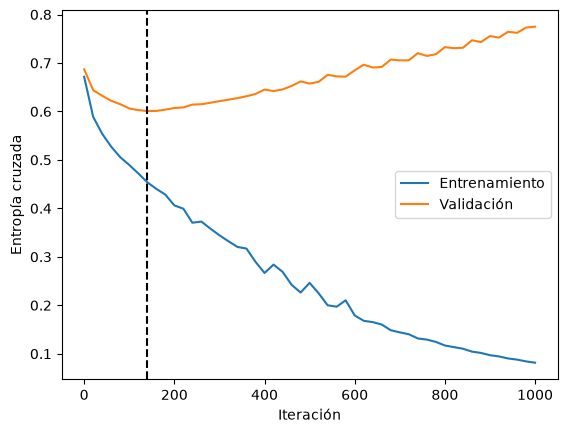

In [4]:
historias, filas_tasas = {}, []
mejor_coste = np.inf
mejores_pesos = None
X_train, X_val = X[:, it], X[:, iv]
with threadpool_limits(limits=1):
    for alpha in [.001, .003, .0075]:
        red = Red([X.shape[0], 20, 7, 1], ['relu', 'relu', 'sigmoid'])
        historia = []
        for paso in range(1001):
            red.forward(X_train)
            gradientes = red.backward(Y[:, it])
            if paso % 20 == 0:
                coste_train = red.coste(X_train, Y[:, it])
                coste_val = red.coste(X_val, Y[:, iv])
                historia.append([paso, coste_train, coste_val])
                if coste_val < mejor_coste:
                    mejor_coste = coste_val
                    mejor_alpha, mejor_paso = alpha, paso
                    mejores_pesos = [(c.W.copy(), c.b.copy()) for c in red.capas]
            if paso < 1000:
                red.actualizar(gradientes, alpha)
        historias[alpha] = np.array(historia)
        mejor = historias[alpha][np.argmin(historias[alpha][:, 2])]
        filas_tasas.append({'alpha': alpha, 'iteracion': int(mejor[0]),
                            'coste_validacion': mejor[2]})
display(pd.DataFrame(filas_tasas))

# Recuperamos el estado elegido con validación.
for capa, (W, b) in zip(red.capas, mejores_pesos):
    capa.W, capa.b = W, b
historia = historias[mejor_alpha]
plt.plot(historia[:, 0], historia[:, 1], label='Entrenamiento')
plt.plot(historia[:, 0], historia[:, 2], label='Validación')
plt.axvline(mejor_paso, color='black', linestyle='--')
plt.xlabel('Iteración')
plt.ylabel('Entropía cruzada')
plt.legend()
plt.show()

## 4. Evaluación

Clasifico con umbral 0.5 y comparo el acierto con predecir siempre no gato, la clase mayoritaria del entrenamiento.

,conjunto,n,accuracy,coste,referencia_no_gato
0,Entrenamiento,167,0.874251,0.453870,0.652695
1,Validación,42,0.714286,0.600943,0.666667
2,Prueba,50,0.600000,0.655493,0.340000


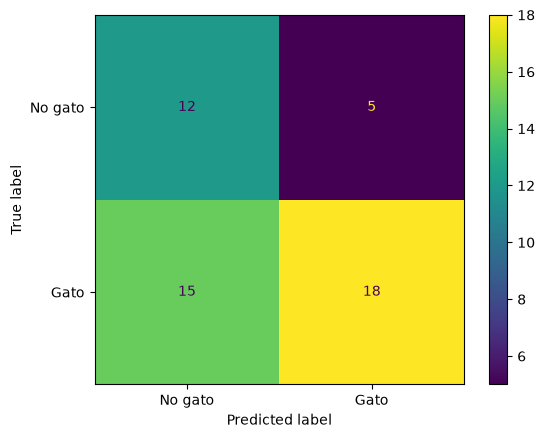

Tasa elegida: 0.003 | iteración: 140
Aciertos en prueba: 30 / 50


In [5]:
filas = []
for nombre, xx, yy in [('Entrenamiento', X[:, it], Y[:, it]),
                       ('Validación', X[:, iv], Y[:, iv]), ('Prueba', X_test, Y_test)]:
    pred = red.forward(xx) >= .5
    filas.append({'conjunto': nombre, 'n': yy.size,
                  'accuracy': np.mean(pred == yy), 'coste': red.coste(xx, yy),
                  'referencia_no_gato': np.mean(yy == 0)})
display(pd.DataFrame(filas))
pred_test = (red.forward(X_test) >= .5).ravel()
ConfusionMatrixDisplay(confusion_matrix(etiquetas_test, pred_test),
                       display_labels=['No gato', 'Gato']).plot()
plt.show()
print('Tasa elegida:', mejor_alpha, '| iteración:', mejor_paso)
print('Aciertos en prueba:', int(np.sum(pred_test == etiquetas_test)), '/', len(etiquetas_test))

## Resultados

La comprobación de gradientes dio un error máximo de 1.1×10⁻¹⁰. Validación eligió alpha = 0.003 y la iteración 140. El acierto fue 87.4 % en entrenamiento, 71.4 % en validación y 60 % en prueba (30 de 50).

En los datos originales hay 72 gatos entre 209 imágenes de entrenamiento y 33 entre 50 de prueba. Ese cambio explica el 34 % de predecir siempre no gato. La tasa menor permite reconocer ambas clases, aunque la diferencia entre entrenamiento y prueba muestra que la generalización sigue siendo limitada.